# Практическая работа №2

## Свёрточные нейронные сети: обнаружение объектов с использованием YOLO


### Техническая инициализация

Устанавливаются актуальная версия Ultralytics с поддержкой YOLO26 и библиотеки для
корректного расчёта detection mAP.

In [ ]:
%pip install -q "ultralytics>=8.3,<9" "torchmetrics>=1.4,<2" "pycocotools>=2.0.7,<3"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 4.7 MB/s eta 0:00:00


In [ ]:
import os
import sys
import gc
import json
import math
import random
import shutil
import subprocess
import time
import warnings
import xml.etree.ElementTree as ET
from collections import Counter, defaultdict
from pathlib import Path
from importlib.metadata import PackageNotFoundError, version as package_version

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
import torchvision
import yaml
from IPython.display import Image as IPImage, display
from PIL import Image, ImageDraw
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.ops import box_iou
from torchvision.transforms.functional import pil_to_tensor
from ultralytics import YOLO
import ultralytics

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    torch.use_deterministic_algorithms(True, warn_only=True)
except Exception:
    pass

IN_COLAB = "google.colab" in sys.modules
PROJECT_ROOT = Path("/content/lab2_yolo") if IN_COLAB else Path.cwd() / "lab2_yolo_runtime"
PROJECT_ROOT.mkdir(parents=True, exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
TORCH_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python:       {sys.version.split()[0]}")
print(f"PyTorch:      {torch.__version__}")
print(f"torchvision:  {torchvision.__version__}")
print(f"Ultralytics:  {ultralytics.__version__}")
print(f"OpenCV:       {cv2.__version__}")
print(f"NumPy:        {np.__version__}")
print(f"Pandas:       {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")


def installed_version(package_name):
    try:
        return package_version(package_name)
    except PackageNotFoundError:
        return "not installed"

ENVIRONMENT_INFO = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "ultralytics": ultralytics.__version__,
    "torchmetrics": installed_version("torchmetrics"),
    "pycocotools": installed_version("pycocotools"),
    "opencv-python": installed_version("opencv-python"),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
}

ENVIRONMENT_JSON = PROJECT_ROOT / "environment.json"
ENVIRONMENT_JSON.write_text(
    json.dumps(ENVIRONMENT_INFO, ensure_ascii=False, indent=2),
    encoding="utf-8",
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python:       3.13.15
PyTorch:      2.11.0+cu128
torchvision:  0.26.0+cu128
Ultralytics:  8.4.150
OpenCV:       5.0.0
NumPy:        2.1.3
Pandas:       2.2.3
scikit-learn: 1.6.1
CUDA доступна: True
GPU: Tesla T4
Рабочий каталог: /content/lab2_yolo
Версии окружения сохранены: /content/lab2_yolo/environment.json


### 1. Цель работы

Цель — освоить полный цикл решения задачи обнаружения объектов: подготовить и проверить
размеченные данные, дообучить современную YOLO26 с переносом обучения, подобрать небольшой
набор гиперпараметров, сравнить размеры YOLO и альтернативную двухэтапную архитектуру
Faster R-CNN, а затем проанализировать метрики и реальные ошибки.

### 2. Краткие теоретические сведения

**Свёрточная нейронная сеть (CNN)** извлекает из изображения иерархические признаки:
от границ и текстур на ранних слоях до частей объектов на глубоких слоях.

**Object detection** одновременно отвечает на два вопроса: *что* находится на изображении
и *где*. Положение объекта задаёт прямоугольник (bounding box) с координатами углов либо
центра, ширины и высоты.

**YOLO (You Only Look Once)** — семейство одноэтапных детекторов. Сеть за один проход
предсказывает классы и рамки, поэтому хорошо подходит для задач, где важна скорость.
На дату подготовки работы официальная документация Ultralytics называет YOLO26 актуальным
семейством и публикует checkpoints `yolo26n.pt`, `yolo26s.pt` и более крупные варианты.
Основной вариант здесь — **YOLO26n**: nano-модель быстрее и экономнее по памяти, что удобно
для Colab. Для сравнения добавлена **YOLO26s**, обычно более точная, но более тяжёлая.

Основные метрики:

- Precision = TP / (TP + FP): доля верных срабатываний среди всех предсказаний.
- Recall = TP / (TP + FN): доля найденных объектов среди всех истинных объектов.
- IoU — отношение площади пересечения двух рамок к площади их объединения.
- AP — площадь под precision–recall-кривой для одного класса; mAP усредняет AP.
- mAP@0.50 использует порог IoU 0.50. mAP@0.50:0.95 усредняет результат по порогам
  от 0.50 до 0.95 с шагом 0.05 и строже оценивает точность локализации.

### 3. Выбор датасета

Выбран **BCCD (Blood Cell Count and Detection)**:

- источник: [Roboflow Public BCCD](https://public.roboflow.com/object-detection/bccd) и
  [исходный репозиторий Shenggan/BCCD_Dataset](https://github.com/Shenggan/BCCD_Dataset);
- 364 изображения размером 640×480;
- 3 класса: `RBC` (эритроциты), `WBC` (лейкоциты), `Platelets` (тромбоциты);
- исходная разметка: Pascal VOC XML с bounding boxes.


### 4. Загрузка и анализ данных

По умолчанию BCCD автоматически загружается из открытого GitHub-репозитория, поэтому
ноутбук запускается в Colab без Google Drive, API-ключей и ручной загрузки архива.
Исходные XML-аннотации преобразуются в YOLO-формат
`class x_center y_center width height` с нормированными координатами. Изображения один раз
перемешиваются с `SEED=42` и делятся в пропорции 70% / 15% / 15%.

In [ ]:
DATASET_REPO = PROJECT_ROOT / "BCCD_Dataset"
DATASET_DIR = PROJECT_ROOT / "bccd_yolo"
SOURCE_URL = "https://github.com/Shenggan/BCCD_Dataset.git"
CLASS_NAMES = ["RBC", "WBC", "Platelets"]
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
DATASET_PROVENANCE_JSON = PROJECT_ROOT / "dataset_provenance.json"

expected_source = DATASET_REPO / "BCCD" / "JPEGImages"
if not expected_source.exists() or len(list(expected_source.glob("*.jpg"))) < 300:
    if DATASET_REPO.exists():
        shutil.rmtree(DATASET_REPO)
    subprocess.run(
        ["git", "clone", "--depth", "1", SOURCE_URL, str(DATASET_REPO)],
        check=True,
    )

dataset_commit = subprocess.check_output(
    ["git", "-C", str(DATASET_REPO), "rev-parse", "HEAD"],
    text=True,
).strip()
dataset_provenance = {
    "source": SOURCE_URL,
    "git_commit": dataset_commit,
    "download_method": "git clone --depth 1",
    "split_seed": SEED,
    "split_ratio": {"train": 0.70, "val": 0.15, "test": 0.15},
}
DATASET_PROVENANCE_JSON.write_text(
    json.dumps(dataset_provenance, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

source_images = DATASET_REPO / "BCCD" / "JPEGImages"
source_xml = DATASET_REPO / "BCCD" / "Annotations"
image_paths = sorted(source_images.glob("*.jpg"))
assert len(image_paths) == 364, f"Ожидалось 364 изображения, найдено {len(image_paths)}"
assert all((source_xml / f"{p.stem}.xml").exists() for p in image_paths)

image_ids = np.array([p.stem for p in image_paths])
train_ids, temp_ids = train_test_split(
    image_ids, test_size=0.30, random_state=SEED, shuffle=True
)
val_ids, test_ids = train_test_split(
    temp_ids, test_size=0.50, random_state=SEED, shuffle=True
)
split_ids = {
    "train": sorted(train_ids.tolist()),
    "val": sorted(val_ids.tolist()),
    "test": sorted(test_ids.tolist()),
}

assert not (set(split_ids["train"]) & set(split_ids["val"]))
assert not (set(split_ids["train"]) & set(split_ids["test"]))
assert not (set(split_ids["val"]) & set(split_ids["test"]))
assert sum(map(len, split_ids.values())) == len(image_ids)

if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
for split in split_ids:
    (DATASET_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

skipped_boxes = []

def clip_voc_box(xmin, ymin, xmax, ymax, image_width, image_height):
    # Нормализуем порядок координат и ограничиваем рамку границами изображения.
    xmin, xmax = sorted((float(xmin), float(xmax)))
    ymin, ymax = sorted((float(ymin), float(ymax)))
    width, height = float(image_width), float(image_height)
    xmin = max(0.0, min(width, xmin))
    xmax = max(0.0, min(width, xmax))
    ymin = max(0.0, min(height, ymin))
    ymax = max(0.0, min(height, ymax))

    return xmin, ymin, xmax, ymax

def voc_box_to_yolo(xmin, ymin, xmax, ymax, image_width, image_height):
    xmin, ymin, xmax, ymax = clip_voc_box(
        xmin, ymin, xmax, ymax, image_width, image_height
    )
    width, height = float(image_width), float(image_height)

    if xmax <= xmin or ymax <= ymin:
        return None

    return (
        ((xmin + xmax) / 2) / width,
        ((ymin + ymax) / 2) / height,
        (xmax - xmin) / width,
        (ymax - ymin) / height,
    )

def voc_xml_to_yolo(xml_path, output_path):
    root = ET.parse(xml_path).getroot()
    width = int(root.findtext("size/width"))
    height = int(root.findtext("size/height"))

    lines = []

    for obj in root.findall("object"):
        class_name = obj.findtext("name").strip()

        if class_name not in CLASS_TO_ID:
            raise ValueError(
                f"Неизвестный класс {class_name!r} в {xml_path.name}"
            )

        box = obj.find("bndbox")

        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        clipped_box = clip_voc_box(xmin, ymin, xmax, ymax, width, height)
        yolo_box = voc_box_to_yolo(xmin, ymin, xmax, ymax, width, height)
        if yolo_box is None:
            skipped_boxes.append({
                "file": xml_path.name,
                "class": class_name,
                "source_box": (xmin, ymin, xmax, ymax),
                "clipped_box": clipped_box,
            })
            warnings.warn(
                f"Пропущена вырожденная рамка: {xml_path.name}, "
                f"класс {class_name}, после clipping {clipped_box}",
                UserWarning,
            )
            continue

        x_center, y_center, box_width, box_height = yolo_box

        lines.append(
            f"{CLASS_TO_ID[class_name]} "
            f"{x_center:.8f} {y_center:.8f} "
            f"{box_width:.8f} {box_height:.8f}"
        )

    output_path.write_text(
        "\n".join(lines) + ("\n" if lines else ""),
        encoding="utf-8",
    )

    return len(lines)

converted_counts = {}
for split, ids in split_ids.items():
    count = 0
    for image_id in ids:
        shutil.copy2(source_images / f"{image_id}.jpg", DATASET_DIR / "images" / split / f"{image_id}.jpg")
        count += voc_xml_to_yolo(
            source_xml / f"{image_id}.xml",
            DATASET_DIR / "labels" / split / f"{image_id}.txt",
        )
    converted_counts[split] = count

data_config = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {idx: name for idx, name in enumerate(CLASS_NAMES)},
}
DATA_YAML = DATASET_DIR / "data.yaml"
DATA_YAML.write_text(
    yaml.safe_dump(data_config, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

split_df = pd.DataFrame(
    {
        "split": list(split_ids),
        "images": [len(split_ids[s]) for s in split_ids],
        "share": [len(split_ids[s]) / len(image_ids) for s in split_ids],
    }
)
display(split_df.style.format({"share": "{:.1%}"}))

BCCD commit: d272fb14cdff6e473fafeeeba32aba5f560e9e43
Описание источника: /content/lab2_yolo/dataset_provenance.json


/tmp/ipykernel_1356/4226302323.py:126: UserWarning: Пропущена вырожденная рамка: BloodImage_00343.xml, класс RBC, после clipping (181.0, 329.0, 181.0, 329.0)
  warnings.warn(
/tmp/ipykernel_1356/4226302323.py:126: UserWarning: Пропущена вырожденная рамка: BloodImage_00338.xml, класс RBC, после clipping (504.0, 337.0, 504.0, 337.0)
  warnings.warn(


,split,images,share
0,train,254,69.8%
1,val,55,15.1%
2,test,55,15.1%


Конфигурация датасета: /content/lab2_yolo/bccd_yolo/data.yaml
path: /content/lab2_yolo/bccd_yolo
train: images/train
val: images/val
test: images/test
names:
  0: RBC
  1: WBC
  2: Platelets



### Обработка некорректных bounding boxes

В исходной разметке BCCD встречаются вырожденные рамки, в том числе в BloodImage_00343.xml. Координаты сначала сортируются и ограничиваются границами изображения. Если после clipping ширина или высота равна нулю, рамка записывается в skipped_boxes, для неё выдаётся предупреждение и она пропускается; остальные объекты изображения и весь датасет продолжают обрабатываться.

In [ ]:
def read_yolo_labels(label_path):
    rows = []
    text = label_path.read_text(encoding="utf-8").strip()
    if not text:
        return rows
    for line_no, line in enumerate(text.splitlines(), start=1):
        parts = line.split()
        if len(parts) != 5:
            raise ValueError(f"{label_path}:{line_no}: ожидалось 5 значений")
        class_id = int(parts[0])
        x, y, w, h = map(float, parts[1:])
        rows.append((class_id, x, y, w, h))
    return rows

class_counts_by_split = {}
image_size_counts = Counter()
for split in split_ids:
    counter = Counter()
    for image_path in sorted((DATASET_DIR / "images" / split).glob("*.jpg")):
        with Image.open(image_path) as img:
            image_size_counts[img.size] += 1
        for class_id, *_ in read_yolo_labels(DATASET_DIR / "labels" / split / f"{image_path.stem}.txt"):
            counter[CLASS_NAMES[class_id]] += 1
    class_counts_by_split[split] = counter

object_stats = pd.DataFrame(class_counts_by_split).fillna(0).astype(int)
object_stats["total"] = object_stats.sum(axis=1)
display(object_stats)
print("Размеры изображений (ширина, высота):", dict(image_size_counts))
print("Всего объектов:", int(object_stats["total"].sum()))

,train,val,test,total
WBC,262,57,53,372
RBC,2856,668,629,4153
Platelets,227,61,73,361


Размеры изображений (ширина, высота): {(640, 480): 364}
Всего объектов: 4886


Полученная таблица показывает фактические размеры частей и число объектов каждого класса.
Для BCCD характерен сильный дисбаланс: эритроцитов заметно больше, чем лейкоцитов и
тромбоцитов. Это следует учитывать при интерпретации средних и поклассовых метрик. Все
исходные кадры имеют одинаковый размер 640×480; растягивать их вручную не требуется —
Ultralytics выполняет letterbox-преобразование до `imgsz`, сохраняя пропорции.

### 5. Проверка разметки

Проверяются пары image–label, пустые и отсутствующие файлы, читаемость изображений,
идентификаторы классов и диапазоны нормированных координат.

In [ ]:
validation_report = []
invalid_rows = []

for split in split_ids:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split
    images = sorted(image_dir.glob("*.jpg"))
    labels = sorted(label_dir.glob("*.txt"))
    image_stems = {p.stem for p in images}
    label_stems = {p.stem for p in labels}
    missing_labels = sorted(image_stems - label_stems)
    orphan_labels = sorted(label_stems - image_stems)
    empty_labels = []
    corrupt_images = []

    for image_path in images:
        try:
            with Image.open(image_path) as img:
                img.verify()
        except Exception as exc:
            corrupt_images.append((image_path.name, str(exc)))

    for label_path in labels:
        rows = read_yolo_labels(label_path)
        if not rows:
            empty_labels.append(label_path.name)
        for row_no, (class_id, x, y, w, h) in enumerate(rows, start=1):
            valid = (
                0 <= class_id < len(CLASS_NAMES)
                and 0 <= x <= 1
                and 0 <= y <= 1
                and 0 < w <= 1
                and 0 < h <= 1
                and x - w / 2 >= -1e-6
                and y - h / 2 >= -1e-6
                and x + w / 2 <= 1 + 1e-6
                and y + h / 2 <= 1 + 1e-6
            )
            if not valid:
                invalid_rows.append((split, label_path.name, row_no, class_id, x, y, w, h))

    validation_report.append(
        {
            "split": split,
            "images": len(images),
            "labels": len(labels),
            "missing_labels": len(missing_labels),
            "orphan_labels": len(orphan_labels),
            "empty_labels": len(empty_labels),
            "corrupt_images": len(corrupt_images),
        }
    )

validation_df = pd.DataFrame(validation_report)
display(validation_df)
assert validation_df[["missing_labels", "orphan_labels", "empty_labels", "corrupt_images"]].to_numpy().sum() == 0
assert not invalid_rows, f"Найдены некорректные строки: {invalid_rows[:5]}"

,split,images,labels,missing_labels,orphan_labels,empty_labels,corrupt_images
0,train,254,254,0,0,0,0
1,val,55,55,0,0,0,0
2,test,55,55,0,0,0,0


Проверка завершена: изображения и аннотации согласованы, координаты корректны.


### 6. Визуализация dataset

Сначала строится распределение классов, затем показываются случайные изображения из
train с исходными bounding boxes.

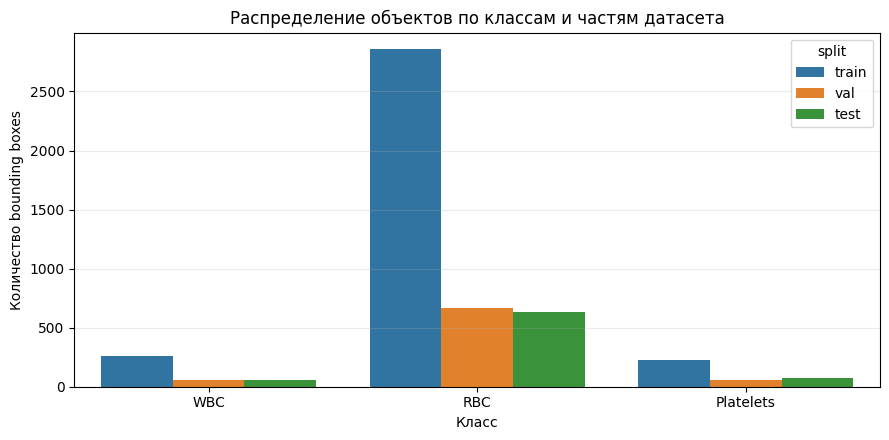

In [ ]:
plot_df = (
    object_stats.drop(columns="total")
    .rename_axis("class")
    .reset_index()
    .melt(id_vars="class", var_name="split", value_name="objects")
)
plt.figure(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="class", y="objects", hue="split")
plt.title("Распределение объектов по классам и частям датасета")
plt.xlabel("Класс")
plt.ylabel("Количество bounding boxes")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

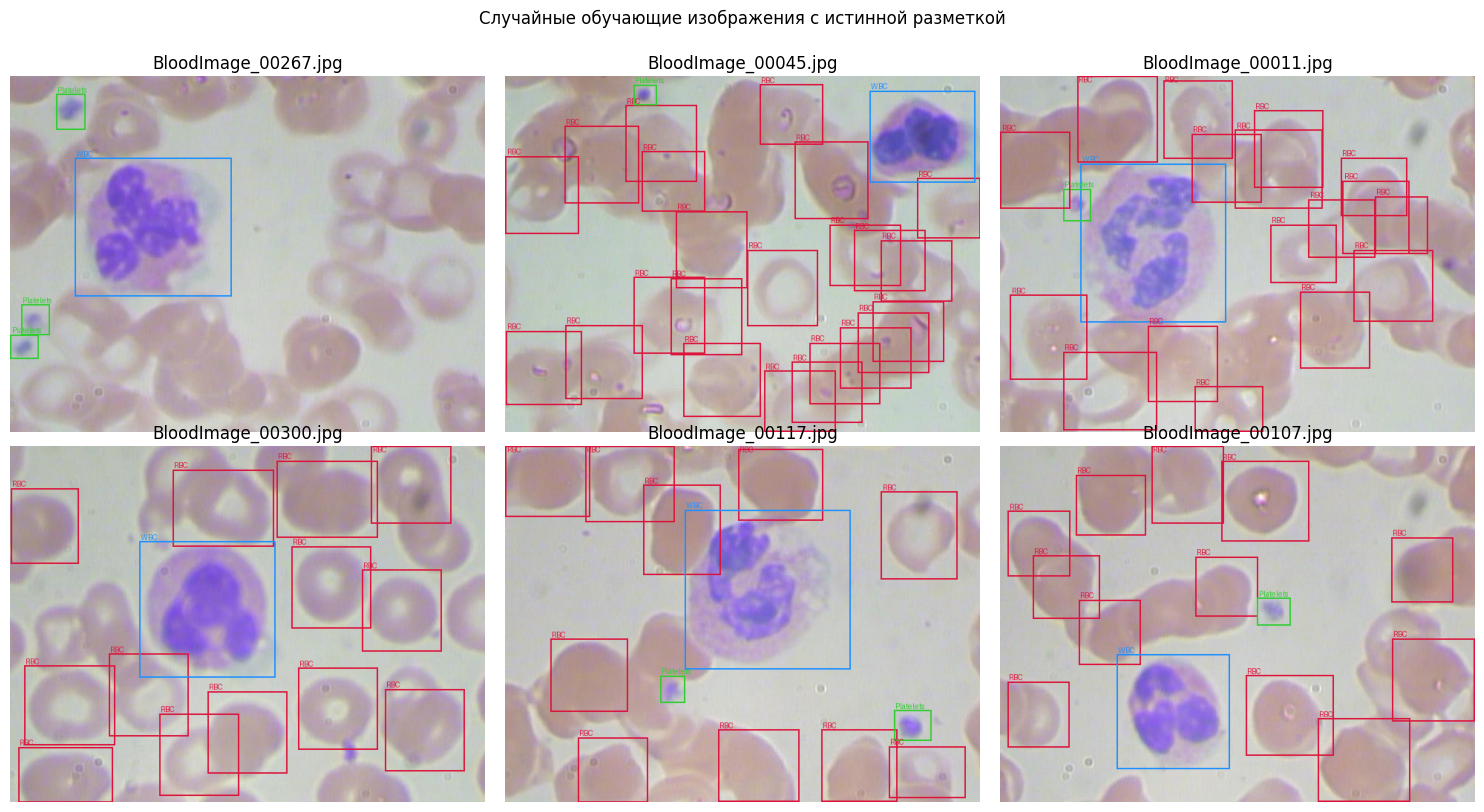

In [ ]:
COLORS = [(220, 20, 60), (30, 144, 255), (50, 205, 50)]

def yolo_box_to_xyxy(row, image_width, image_height):
    class_id, x, y, w, h = row
    x1 = (x - w / 2) * image_width
    y1 = (y - h / 2) * image_height
    x2 = (x + w / 2) * image_width
    y2 = (y + h / 2) * image_height
    return class_id, x1, y1, x2, y2

def draw_ground_truth(image_path):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    rows = read_yolo_labels(DATASET_DIR / "labels" / image_path.parent.name / f"{image_path.stem}.txt")
    for row in rows:
        class_id, x1, y1, x2, y2 = yolo_box_to_xyxy(row, *image.size)
        color = COLORS[class_id]
        draw.rectangle((x1, y1, x2, y2), outline=color, width=2)
        draw.text((x1 + 2, max(0, y1 - 12)), CLASS_NAMES[class_id], fill=color)
    return image

rng = random.Random(SEED)
train_examples = rng.sample(sorted((DATASET_DIR / "images" / "train").glob("*.jpg")), k=6)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, image_path in zip(axes.ravel(), train_examples):
    ax.imshow(draw_ground_truth(image_path))
    ax.set_title(image_path.name)
    ax.axis("off")
plt.suptitle("Случайные обучающие изображения с истинной разметкой", y=1.01)
plt.tight_layout()
plt.show()

### 7. Подготовка среды

In [ ]:
RUNS_ROOT = PROJECT_ROOT / "runs"
RUNS_ROOT.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = [
    {
        "experiment": "baseline_n",
        "model": "yolo26n.pt",
        "epochs": 20,
        "batch": 16,
        "imgsz": 512,
        "optimizer": "SGD",
        "lr0": 0.01,
        "degrees": 0.0,
        "translate": 0.10,
        "scale": 0.50,
        "fliplr": 0.50,
        "mosaic": 1.00,
    },
    {
        "experiment": "n_tuned_aug",
        "model": "yolo26n.pt",
        "epochs": 30,
        "batch": 16,
        "imgsz": 512,
        "optimizer": "AdamW",
        "lr0": 0.003,
        "degrees": 7.0,
        "translate": 0.10,
        "scale": 0.40,
        "fliplr": 0.50,
        "mosaic": 0.80,
    },
    {
        "experiment": "s_highres",
        "model": "yolo26s.pt",
        "epochs": 25,
        "batch": 8,
        "imgsz": 640,
        "optimizer": "AdamW",
        "lr0": 0.003,
        "degrees": 7.0,
        "translate": 0.10,
        "scale": 0.40,
        "fliplr": 0.50,
        "mosaic": 0.80,
    },
]
display(pd.DataFrame(EXPERIMENTS))

,experiment,model,epochs,batch,imgsz,optimizer,lr0,degrees,translate,scale,fliplr,mosaic
0,baseline_n,yolo26n.pt,20,16,512,SGD,0.010,0.0,0.1,0.5,0.5,1.0
1,n_tuned_aug,yolo26n.pt,30,16,512,AdamW,0.003,7.0,0.1,0.4,0.5,0.8
2,s_highres,yolo26s.pt,25,8,640,AdamW,0.003,7.0,0.1,0.4,0.5,0.8


In [ ]:
TEST_IMAGE_PATHS = sorted((DATASET_DIR / "images" / "test").glob("*.jpg"))

def metric_summary(metrics):
    return {
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "map50": float(metrics.box.map50),
        "map50_95": float(metrics.box.map),
    }

def per_class_metrics(metrics, split_name):
    box = metrics.box
    class_ids = np.asarray(getattr(box, "ap_class_index", []), dtype=int)
    precision = np.asarray(getattr(box, "p", []), dtype=float)
    recall = np.asarray(getattr(box, "r", []), dtype=float)
    ap50 = np.asarray(getattr(box, "ap50", []), dtype=float)
    maps = np.asarray(getattr(box, "maps", []), dtype=float)
    rows = []
    for idx, class_id in enumerate(class_ids):
        rows.append(
            {
                "split": split_name,
                "class_id": int(class_id),
                "class": CLASS_NAMES[int(class_id)],
                "precision": float(precision[idx]) if idx < len(precision) else np.nan,
                "recall": float(recall[idx]) if idx < len(recall) else np.nan,
                "mAP50": float(ap50[idx]) if idx < len(ap50) else np.nan,
                "mAP50-95": float(maps[int(class_id)]) if int(class_id) < len(maps) else np.nan,
            }
        )
    return pd.DataFrame(rows)

def measure_yolo_speed(model, image_paths, imgsz):
    sample = [str(p) for p in image_paths[: min(20, len(image_paths))]]
    if not sample:
        return float("nan")
    _ = model.predict(sample[0], imgsz=imgsz, device=DEVICE, verbose=False)
    results = model.predict(sample, imgsz=imgsz, device=DEVICE, verbose=False)
    return float(np.mean([result.speed["inference"] for result in results]))

def run_yolo_experiment(config):
    print(f"\n=== {config['experiment']} ({config['model']}) ===")
    model = YOLO(config["model"])
    started = time.perf_counter()
    model.train(
        data=str(DATA_YAML),
        epochs=config["epochs"],
        batch=config["batch"],
        imgsz=config["imgsz"],
        optimizer=config["optimizer"],
        lr0=config["lr0"],
        degrees=config["degrees"],
        translate=config["translate"],
        scale=config["scale"],
        fliplr=config["fliplr"],
        mosaic=config["mosaic"],
        close_mosaic=5,
        patience=8,
        pretrained=True,
        seed=SEED,
        deterministic=True,
        device=DEVICE,
        workers=2,
        amp=torch.cuda.is_available(),
        project=str(RUNS_ROOT / "train"),
        name=config["experiment"],
        exist_ok=True,
        plots=True,
        verbose=False,
    )
    training_time = time.perf_counter() - started
    train_dir = Path(model.trainer.save_dir)
    results_csv = train_dir / "results.csv"
    epochs_completed = (
        len(pd.read_csv(results_csv))
        if results_csv.exists()
        else config["epochs"]
    )

    checkpoint = train_dir / "weights" / "best.pt"
    if not checkpoint.exists():
        checkpoint = train_dir / "weights" / "last.pt"
    assert checkpoint.exists(), f"Checkpoint не найден в {train_dir}"

    fitted = YOLO(str(checkpoint))
    val_dir = RUNS_ROOT / "eval" / f"{config['experiment']}_val"
    test_dir = RUNS_ROOT / "eval" / f"{config['experiment']}_test"
    val_metrics = fitted.val(
        data=str(DATA_YAML), split="val", imgsz=config["imgsz"], batch=config["batch"],
        device=DEVICE, plots=True, project=str(RUNS_ROOT / "eval"),
        name=f"{config['experiment']}_val", exist_ok=True, verbose=False,
    )
    test_metrics = fitted.val(
        data=str(DATA_YAML), split="test", imgsz=config["imgsz"], batch=config["batch"],
        device=DEVICE, plots=False, project=str(RUNS_ROOT / "eval"),
        name=f"{config['experiment']}_test", exist_ok=True, verbose=False,
    )
    val_summary = metric_summary(val_metrics)
    test_summary = metric_summary(test_metrics)
    inference_ms = measure_yolo_speed(fitted, TEST_IMAGE_PATHS, config["imgsz"])
    parameters = sum(p.numel() for p in fitted.model.parameters())

    record = dict(config)
    record.update(
        {
            "training_time_s": training_time,
            "epochs_completed": epochs_completed,
            "training_time_per_epoch_s": training_time / max(1, epochs_completed),
            "timing_scope": "train + validation внутри model.train",
            "inference_ms": inference_ms,
            "parameters": parameters,
            "checkpoint_mb": checkpoint.stat().st_size / 1024**2,
            "checkpoint": str(checkpoint),
            "train_dir": str(train_dir),
            "val_dir": str(val_dir),
            "test_dir": str(test_dir),
            **{f"val_{k}": v for k, v in val_summary.items()},
            **{f"test_{k}": v for k, v in test_summary.items()},
            "val_per_class": per_class_metrics(val_metrics, "validation"),
            "test_per_class": per_class_metrics(test_metrics, "test"),
        }
    )
    print(f"best checkpoint: {checkpoint}")
    print(f"завершено эпох: {epochs_completed}")
    print(f"время fit (train + validation): {training_time / 60:.2f} min")
    return record


### 8. Baseline YOLO

In [ ]:
experiment_records = []
baseline_record = run_yolo_experiment(EXPERIMENTS[0])
experiment_records.append(baseline_record)

baseline_overview = pd.DataFrame(
    [
        {
            "split": "validation",
            "Precision": baseline_record["val_precision"],
            "Recall": baseline_record["val_recall"],
            "mAP50": baseline_record["val_map50"],
            "mAP50-95": baseline_record["val_map50_95"],
        },
        {
            "split": "test",
            "Precision": baseline_record["test_precision"],
            "Recall": baseline_record["test_recall"],
            "mAP50": baseline_record["test_map50"],
            "mAP50-95": baseline_record["test_map50_95"],
        },
    ]
)
display(baseline_overview.style.format({c: "{:.4f}" for c in baseline_overview.columns if c != "split"}))


=== baseline_n (yolo26n.pt) ===
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lab2_yolo/bccd_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseli

,split,Precision,Recall,mAP50,mAP50-95
0,validation,0.8814,0.9043,0.9187,0.6070
1,test,0.8187,0.9113,0.9048,0.6107


Параметров: 2,504,970
Размер checkpoint: 5.11 MB


### 9. Оценка качества baseline

На этом этапе выводятся поклассовые метрики исходной baseline-конфигурации. Графики обучения,
confusion matrix, PR- и F1-кривые строятся ниже уже для автоматически выбранной лучшей модели.


In [ ]:
baseline_metrics_df = pd.concat(
    [baseline_record["val_per_class"], baseline_record["test_per_class"]],
    ignore_index=True,
)
display(
    baseline_metrics_df.style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "mAP50": "{:.4f}",
            "mAP50-95": "{:.4f}",
        }
    )
)


### 10. Подбор гиперпараметров

Запускаются ещё два эксперимента.

In [ ]:
for config in EXPERIMENTS[1:]:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    experiment_records.append(run_yolo_experiment(config))

experiment_table = pd.DataFrame(
    [
        {
            "experiment": r["experiment"],
            "model": r["model"],
            "planned_epochs": r["epochs"],
            "completed_epochs": r["epochs_completed"],
            "batch": r["batch"],
            "imgsz": r["imgsz"],
            "optimizer": r["optimizer"],
            "learning_rate": r["lr0"],
            "precision": r["val_precision"],
            "recall": r["val_recall"],
            "mAP50": r["val_map50"],
            "mAP50-95": r["val_map50_95"],
            "fit_train_val_time_s": r["training_time_s"],
            "time_per_epoch_s": r["training_time_per_epoch_s"],
            "inference_ms": r["inference_ms"],
            "parameters": r["parameters"],
            "checkpoint_mb": r["checkpoint_mb"],
        }
        for r in experiment_records
    ]
).sort_values("mAP50-95", ascending=False).reset_index(drop=True)

display(
    experiment_table.style.format(
        {
            "learning_rate": "{:.4g}",
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "mAP50": "{:.4f}",
            "mAP50-95": "{:.4f}",
            "fit_train_val_time_s": "{:.1f}",
            "time_per_epoch_s": "{:.1f}",
            "inference_ms": "{:.2f}",
            "parameters": "{:,}",
            "checkpoint_mb": "{:.2f}",
        }
    ).background_gradient(subset=["mAP50-95"], cmap="Greens")
)

best_record = max(experiment_records, key=lambda r: r["val_map50_95"])
best_yolo = YOLO(best_record["checkpoint"])
print(
    f"Лучший эксперимент по validation mAP50-95: {best_record['experiment']} "
    f"({best_record['model']}), mAP50-95={best_record['val_map50_95']:.4f}"
)



=== n_tuned_aug (yolo26n.pt) ===
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/lab2_yolo/bccd_yolo/data.yaml, degrees=7.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.8, multi_scale=0.0, name=n_tu

,experiment,model,planned_epochs,completed_epochs,batch,imgsz,optimizer,learning_rate,precision,recall,mAP50,mAP50-95,fit_train_val_time_s,time_per_epoch_s,inference_ms,parameters,checkpoint_mb
0,n_tuned_aug,yolo26n.pt,30,26,16,512,AdamW,0.003,0.8452,0.9307,0.9349,0.6073,148.3,5.7,1.72,"2,504,970",5.11
1,baseline_n,yolo26n.pt,20,20,16,512,SGD,0.01,0.8814,0.9043,0.9187,0.6070,160.0,8.0,3.49,"2,504,970",5.11
2,s_highres,yolo26s.pt,25,25,8,640,AdamW,0.003,0.9089,0.9053,0.9416,0.6003,252.7,10.1,7.88,"9,950,186",19.36


Лучший эксперимент по validation mAP50-95: n_tuned_aug (yolo26n.pt), mAP50-95=0.6073


### Графики обучения лучшей YOLO-конфигурации

Метрики разделены на Precision/Recall и mAP, а лучшая эпоха отмечается по validation mAP50-95.


In [ ]:
FIGURES_DIR = RUNS_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

best_history_path = Path(best_record["train_dir"]) / "results.csv"
best_history = pd.read_csv(best_history_path)
best_history.columns = best_history.columns.str.strip()

loss_specs = [
    ("box_loss", "Ошибка локализации рамок"),
    ("cls_loss", "Ошибка классификации"),
    ("l1_loss", "L1-ошибка координат"),
]
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, (suffix, title) in zip(axes, loss_specs):
    train_column = f"train/{suffix}"
    val_column = f"val/{suffix}"
    plotted = False
    if train_column in best_history:
        ax.plot(
            best_history["epoch"],
            best_history[train_column],
            linewidth=2,
            label=f"Обучение: {best_history[train_column].iloc[-1]:.3f}",
        )
        plotted = True
    if val_column in best_history:
        ax.plot(
            best_history["epoch"],
            best_history[val_column],
            linewidth=2,
            label=f"Валидация: {best_history[val_column].iloc[-1]:.3f}",
        )
        plotted = True
    ax.set_title(title)
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.25)
    if plotted:
        ax.legend()
    else:
        ax.text(0.5, 0.5, "Метрика отсутствует", ha="center", va="center")

fig.suptitle(
    f"Динамика loss лучшей модели: {best_record['experiment']} ({best_record['model']})",
    fontsize=14,
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(FIGURES_DIR / "best_yolo_losses.png", dpi=180, bbox_inches="tight")
plt.show()

precision_column = "metrics/precision(B)"
recall_column = "metrics/recall(B)"
map50_column = "metrics/mAP50(B)"
map_column = "metrics/mAP50-95(B)"

if map_column not in best_history:
    raise KeyError(f"В {best_history_path} отсутствует {map_column}")

best_row_index = best_history[map_column].idxmax()
best_epoch = int(best_history.loc[best_row_index, "epoch"])
best_map = float(best_history.loc[best_row_index, map_column])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for column, label in [
    (precision_column, "Precision"),
    (recall_column, "Recall"),
]:
    if column in best_history:
        axes[0].plot(best_history["epoch"], best_history[column], linewidth=2, label=label)
axes[0].set_title("Точность и полнота на validation")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Значение")
axes[0].set_ylim(0, 1.02)
axes[0].grid(alpha=0.25)
axes[0].legend()

for column, label in [
    (map50_column, "mAP50"),
    (map_column, "mAP50-95"),
]:
    if column in best_history:
        axes[1].plot(best_history["epoch"], best_history[column], linewidth=2, label=label)
axes[1].scatter(best_epoch, best_map, color="crimson", s=70, zorder=5)
axes[1].annotate(
    f"Лучшая эпоха: {best_epoch}\nmAP50-95 = {best_map:.3f}",
    xy=(best_epoch, best_map),
    xytext=(10, -42),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "crimson"},
)
axes[1].set_title("Качество обнаружения на validation")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Значение")
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.suptitle(
    f"Validation-метрики лучшей модели: {best_record['experiment']} ({best_record['model']})",
    fontsize=14,
)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(FIGURES_DIR / "best_yolo_validation_metrics.png", dpi=180, bbox_inches="tight")
plt.show()

print(
    f"Лучшая эпоха по validation mAP50-95: {best_epoch}; "
    f"mAP50-95 = {best_map:.4f}."
)

plot_specs = [
    (
        "Нормализованная матрица ошибок",
        ["confusion_matrix_normalized.png"],
    ),
    (
        "Precision–Recall-кривая",
        ["BoxPR_curve.png", "PR_curve.png"],
    ),
    (
        "F1-кривая и выбор confidence threshold",
        ["BoxF1_curve.png", "F1_curve.png"],
    ),
]
search_roots = [Path(best_record["val_dir"]), Path(best_record["train_dir"])]

for title, filenames in plot_specs:
    found_path = None
    for root in search_roots:
        for filename in filenames:
            matches = sorted(root.rglob(filename)) if root.exists() else []
            if matches:
                found_path = matches[0]
                break
        if found_path is not None:
            break

    print(title)
    if found_path is None:
        print(f"Файл не найден. Проверены: {[str(path) for path in search_roots]}")
    else:
        print(found_path)
        display(IPImage(filename=str(found_path), width=900))


Лучшая конфигурация выбирается программно только по validation mAP50-95. Test-метрики не
участвуют в выборе, поэтому остаются более честной оценкой обобщающей способности.

### 11. Сравнение версий YOLO

Таблица выше одновременно сравнивает nano и small по качеству, времени обучения, скорости,
числу параметров и размеру checkpoint. Ниже генерируется краткий вывод по фактическим данным.

In [ ]:
nano_rows = experiment_table[experiment_table["model"] == "yolo26n.pt"]
small_rows = experiment_table[experiment_table["model"] == "yolo26s.pt"]
best_nano = nano_rows.loc[nano_rows["mAP50-95"].idxmax()]
best_small = small_rows.loc[small_rows["mAP50-95"].idxmax()]

more_accurate = best_nano if best_nano["mAP50-95"] >= best_small["mAP50-95"] else best_small
faster = best_nano if best_nano["inference_ms"] <= best_small["inference_ms"] else best_small
print(
    f"По validation mAP50-95 лучше: {more_accurate['experiment']} "
    f"({more_accurate['mAP50-95']:.4f})."
)
print("Поклассовые метрики автоматически выбранной лучшей YOLO:")
display(
    pd.concat([best_record["val_per_class"], best_record["test_per_class"]], ignore_index=True)
    .style.format({"precision": "{:.4f}", "recall": "{:.4f}", "mAP50": "{:.4f}", "mAP50-95": "{:.4f}"})
)

По validation mAP50-95 лучше: n_tuned_aug (0.6073).
Быстрее на текущем устройстве: n_tuned_aug (1.72 мс/изображение).
YOLO26s содержит 3.97× параметров по сравнению с YOLO26n в этих запусках.
Поклассовые метрики автоматически выбранной лучшей YOLO:


,split,class_id,class,precision,recall,mAP50,mAP50-95
0,validation,0,RBC,0.7653,0.8578,0.8804,0.6114
1,validation,1,WBC,0.9511,1.0000,0.9914,0.7633
2,validation,2,Platelets,0.8190,0.9344,0.9328,0.4471
3,test,0,RBC,0.7724,0.8331,0.8707,0.5896
4,test,1,WBC,0.9316,1.0000,0.9862,0.7679
5,test,2,Platelets,0.8495,0.8502,0.8401,0.4468


### 12. Альтернативная модель

В качестве принципиально другой архитектуры используется **Faster R-CNN с
MobileNetV3-Large FPN** из torchvision. Это двухэтапный детектор: сначала генерируются
кандидаты областей, затем они классифицируются и уточняются. MobileNet-backbone выбран вместо
ResNet50, чтобы ограниченное дообучение было реально выполнить в Colab. COCO-pretrained веса
сохраняются, а последний классификатор заменяется на 3 класса BCCD + обязательный background.

In [ ]:
from torchvision.models.detection import (
    FasterRCNN_MobileNet_V3_Large_FPN_Weights,
    fasterrcnn_mobilenet_v3_large_fpn,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


class YoloDetectionDataset(Dataset):
    def __init__(self, dataset_root, split):
        self.image_dir = Path(dataset_root) / "images" / split
        self.label_dir = Path(dataset_root) / "labels" / split
        self.images = sorted(self.image_dir.glob("*.jpg"))

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image_path = self.images[index]
        image_pil = Image.open(image_path).convert("RGB")
        width, height = image_pil.size
        boxes, labels = [], []
        for row in read_yolo_labels(self.label_dir / f"{image_path.stem}.txt"):
            class_id, x1, y1, x2, y2 = yolo_box_to_xyxy(row, width, height)
            boxes.append([x1, y1, x2, y2])
            labels.append(class_id + 1)  # 0 зарезервирован под background
        target = {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor(index, dtype=torch.int64),
            "area": torch.as_tensor(
                [(x2 - x1) * (y2 - y1) for x1, y1, x2, y2 in boxes], dtype=torch.float32
            ),
            "iscrowd": torch.zeros(len(boxes), dtype=torch.int64),
        }
        image = pil_to_tensor(image_pil).float() / 255.0
        return image, target

def collate_detection(batch):
    return tuple(zip(*batch))

fr_train_dataset = YoloDetectionDataset(DATASET_DIR, "train")
fr_val_dataset = YoloDetectionDataset(DATASET_DIR, "val")
fr_test_dataset = YoloDetectionDataset(DATASET_DIR, "test")
FR_BATCH_SIZE = 4 if torch.cuda.is_available() else 2
FR_EPOCHS = 5

generator = torch.Generator().manual_seed(SEED)
fr_train_loader = DataLoader(
    fr_train_dataset, batch_size=FR_BATCH_SIZE, shuffle=True, num_workers=2,
    collate_fn=collate_detection, generator=generator, pin_memory=torch.cuda.is_available()
)
fr_val_loader = DataLoader(
    fr_val_dataset, batch_size=FR_BATCH_SIZE, shuffle=False, num_workers=2,
    collate_fn=collate_detection, pin_memory=torch.cuda.is_available()
)
fr_test_loader = DataLoader(
    fr_test_dataset, batch_size=FR_BATCH_SIZE, shuffle=False, num_workers=2,
    collate_fn=collate_detection, pin_memory=torch.cuda.is_available()
)

fr_weights = FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT
faster_rcnn = fasterrcnn_mobilenet_v3_large_fpn(
    weights=fr_weights, min_size=512, max_size=768
)
in_features = faster_rcnn.roi_heads.box_predictor.cls_score.in_features
faster_rcnn.roi_heads.box_predictor = FastRCNNPredictor(
    in_features, len(CLASS_NAMES) + 1
)
faster_rcnn.to(TORCH_DEVICE)

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 189MB/s]


Faster R-CNN параметров: 18,940,479


In [ ]:
def precision_recall_at_threshold(
    predictions,
    targets,
    score_threshold=0.25,
    iou_threshold=0.5,
):
    tp = fp = fn = 0
    for prediction, target in zip(predictions, targets):
        keep = prediction["scores"] >= score_threshold
        pred_boxes = prediction["boxes"][keep]
        pred_labels = prediction["labels"][keep]
        pred_scores = prediction["scores"][keep]
        gt_boxes = target["boxes"]
        gt_labels = target["labels"]
        matched_gt = set()
        order = torch.argsort(pred_scores, descending=True)
        for pred_idx in order.tolist():
            candidates = [
                gt_idx for gt_idx in range(len(gt_boxes))
                if gt_idx not in matched_gt
                and int(gt_labels[gt_idx]) == int(pred_labels[pred_idx])
            ]
            if not candidates:
                fp += 1
                continue
            ious = box_iou(
                pred_boxes[pred_idx].unsqueeze(0),
                gt_boxes[candidates],
            ).squeeze(0)
            best_local = int(torch.argmax(ious))
            if float(ious[best_local]) >= iou_threshold:
                matched_gt.add(candidates[best_local])
                tp += 1
            else:
                fp += 1
        fn += len(gt_boxes) - len(matched_gt)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return precision, recall, tp, fp, fn

@torch.inference_mode()
def evaluate_torchvision_detector(model, loader, split_name):
    model.eval()
    map_metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=True,
    )
    all_predictions, all_targets = [], []
    forward_seconds = 0.0
    image_count = 0

    for images, targets in loader:
        images_device = [
            image.to(TORCH_DEVICE, non_blocking=True)
            for image in images
        ]
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start = time.perf_counter()
        outputs = model(images_device)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        forward_seconds += time.perf_counter() - start
        image_count += len(images)

        predictions_cpu = [
            {key: value.detach().cpu() for key, value in output.items()}
            for output in outputs
        ]
        targets_cpu = [
            {key: value.detach().cpu() for key, value in target.items()}
            for target in targets
        ]
        map_metric.update(predictions_cpu, targets_cpu)
        all_predictions.extend(predictions_cpu)
        all_targets.extend(targets_cpu)

    computed = map_metric.compute()
    precision, recall, tp, fp, fn = precision_recall_at_threshold(
        all_predictions,
        all_targets,
        score_threshold=0.25,
        iou_threshold=0.5,
    )
    summary = {
        "split": split_name,
        "precision": precision,
        "recall": recall,
        "mAP50": float(computed["map_50"]),
        "mAP50-95": float(computed["map"]),
        "inference_ms": 1000 * forward_seconds / max(1, image_count),
        "TP": tp,
        "FP": fp,
        "FN": fn,
    }
    per_class = []
    for class_id, class_map, class_mar in zip(
        computed["classes"].tolist(),
        computed["map_per_class"].tolist(),
        computed["mar_100_per_class"].tolist(),
    ):
        per_class.append(
            {
                "split": split_name,
                "class": CLASS_NAMES[int(class_id) - 1],
                "mAP50-95": class_map,
                "mAR100": class_mar,
            }
        )
    return summary, pd.DataFrame(per_class)

fr_optimizer = torch.optim.AdamW(
    [p for p in faster_rcnn.parameters() if p.requires_grad],
    lr=5e-4,
    weight_decay=1e-4,
)
fr_scheduler = torch.optim.lr_scheduler.StepLR(
    fr_optimizer,
    step_size=3,
    gamma=0.2,
)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

FR_CHECKPOINT = PROJECT_ROOT / "fasterrcnn_mobilenetv3_bccd_best.pt"
faster_rcnn.roi_heads.score_thresh = 0.001
fr_history = []
best_fr_val_map = -float("inf")
fr_started = time.perf_counter()

for epoch in range(FR_EPOCHS):
    epoch_started = time.perf_counter()
    faster_rcnn.train()
    running_loss = 0.0

    for images, targets in fr_train_loader:
        images = [
            image.to(TORCH_DEVICE, non_blocking=True)
            for image in images
        ]
        targets = [
            {
                key: value.to(TORCH_DEVICE, non_blocking=True)
                for key, value in target.items()
            }
            for target in targets
        ]
        fr_optimizer.zero_grad(set_to_none=True)
        with torch.autocast(
            device_type=TORCH_DEVICE.type,
            dtype=torch.float16,
            enabled=torch.cuda.is_available(),
        ):
            loss_dict = faster_rcnn(images, targets)
            loss = sum(loss_dict.values())
        scaler.scale(loss).backward()
        scaler.step(fr_optimizer)
        scaler.update()
        running_loss += float(loss.detach().cpu())

    fr_scheduler.step()
    epoch_loss = running_loss / max(1, len(fr_train_loader))
    val_metrics_epoch, _ = evaluate_torchvision_detector(
        faster_rcnn,
        fr_val_loader,
        "validation",
    )
    val_map = val_metrics_epoch["mAP50-95"]

    if val_map > best_fr_val_map:
        best_fr_val_map = val_map
        torch.save(faster_rcnn.state_dict(), FR_CHECKPOINT)

    epoch_time = time.perf_counter() - epoch_started
    fr_history.append(
        {
            "epoch": epoch + 1,
            "train_loss": epoch_loss,
            "val_mAP50-95": val_map,
            "lr": fr_optimizer.param_groups[0]["lr"],
            "epoch_time_s": epoch_time,
        }
    )
    print(
        f"Epoch {epoch + 1}/{FR_EPOCHS}: "
        f"loss={epoch_loss:.4f}, val mAP50-95={val_map:.4f}"
    )

fr_training_time = time.perf_counter() - fr_started
faster_rcnn.load_state_dict(
    torch.load(
        FR_CHECKPOINT,
        map_location=TORCH_DEVICE,
        weights_only=True,
    )
)

fr_history_df = pd.DataFrame(fr_history)
display(fr_history_df)

best_fr_row = fr_history_df.loc[fr_history_df["val_mAP50-95"].idxmax()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(
    fr_history_df["epoch"],
    fr_history_df["train_loss"],
    marker="o",
    linewidth=2,
)
axes[0].set_title("Faster R-CNN: ошибка на обучении")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.25)

axes[1].plot(
    fr_history_df["epoch"],
    fr_history_df["val_mAP50-95"],
    marker="o",
    linewidth=2,
)
axes[1].scatter(
    best_fr_row["epoch"],
    best_fr_row["val_mAP50-95"],
    color="crimson",
    s=70,
    zorder=5,
)
axes[1].annotate(
    f"Лучшая эпоха: {int(best_fr_row['epoch'])}\n"
    f"mAP50-95 = {best_fr_row['val_mAP50-95']:.3f}",
    xy=(best_fr_row["epoch"], best_fr_row["val_mAP50-95"]),
    xytext=(-92, -42),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "crimson"},
)
axes[1].set_title("Faster R-CNN: качество на validation")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("mAP50-95")
axes[1].grid(alpha=0.25)

fig.suptitle("Динамика обучения Faster R-CNN", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.savefig(FIGURES_DIR / "faster_rcnn_training.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"Лучший validation mAP50-95: {best_fr_val_map:.4f}")
print(f"Время fit (train + validation): {fr_training_time / 60:.2f} min")
print(f"Checkpoint: {FR_CHECKPOINT} ({FR_CHECKPOINT.stat().st_size / 1024**2:.2f} MB)")


In [ ]:
# Оценка выполняется после загрузки лучшего validation-checkpoint.
fr_val_metrics, fr_val_per_class = evaluate_torchvision_detector(
    faster_rcnn, fr_val_loader, "validation"
)
fr_test_metrics, fr_test_per_class = evaluate_torchvision_detector(
    faster_rcnn, fr_test_loader, "test"
)
fr_metrics_df = pd.DataFrame([fr_val_metrics, fr_test_metrics])
display(fr_metrics_df.style.format({
    "precision": "{:.4f}", "recall": "{:.4f}", "mAP50": "{:.4f}",
    "mAP50-95": "{:.4f}", "inference_ms": "{:.2f}"
}))
display(pd.concat([fr_val_per_class, fr_test_per_class], ignore_index=True))


,split,precision,recall,mAP50,mAP50-95,inference_ms,TP,FP,FN
0,validation,0.8176,0.8613,0.8719,0.5549,20.54,677,151,109
1,test,0.7710,0.8649,0.9077,0.5778,14.43,653,194,102


,split,class,mAP50-95,mAR100
0,validation,RBC,0.582421,0.688174
1,validation,WBC,0.783746,0.828070
2,validation,Platelets,0.298533,0.450820
3,test,RBC,0.569228,0.681240
4,test,WBC,0.763701,0.811321
5,test,Platelets,0.400420,0.506849


### 13. Сравнение моделей

Сравниваются test-результаты лучшей YOLO (выбранной по validation) и Faster R-CNN.
Скорость измерена на одном и том же устройстве текущей сессии, поэтому переносить её как
абсолютный benchmark на другое оборудование нельзя. Для честного сравнения Precision и
Recall обеих архитектур пересчитываются при одинаковых порогах confidence ≥ 0.25 и IoU ≥ 0.50.

In [ ]:
def yolo_predictions_and_targets(model, image_paths, imgsz):
    results = model.predict(
        source=[str(path) for path in image_paths], imgsz=imgsz,
        conf=0.001, device=DEVICE, verbose=False
    )
    predictions, targets = [], []
    for image_path, result in zip(image_paths, results):
        if result.boxes is None:
            prediction = {
                "boxes": torch.empty((0, 4)),
                "labels": torch.empty((0,), dtype=torch.int64),
                "scores": torch.empty((0,)),
            }
        else:
            prediction = {
                "boxes": result.boxes.xyxy.detach().cpu().float(),
                "labels": result.boxes.cls.detach().cpu().long() + 1,
                "scores": result.boxes.conf.detach().cpu().float(),
            }
        with Image.open(image_path) as image:
            width, height = image.size
        gt_boxes, gt_labels = [], []
        label_path = DATASET_DIR / "labels" / "test" / f"{image_path.stem}.txt"
        for row in read_yolo_labels(label_path):
            class_id, x1, y1, x2, y2 = yolo_box_to_xyxy(row, width, height)
            gt_boxes.append([x1, y1, x2, y2])
            gt_labels.append(class_id + 1)
        target = {
            "boxes": torch.as_tensor(gt_boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.as_tensor(gt_labels, dtype=torch.int64),
        }
        predictions.append(prediction)
        targets.append(target)
    return predictions, targets

best_yolo_predictions, best_yolo_targets = yolo_predictions_and_targets(
    best_yolo, TEST_IMAGE_PATHS, best_record["imgsz"]
)
yolo_common_precision, yolo_common_recall, yolo_tp, yolo_fp, yolo_fn = precision_recall_at_threshold(
    best_yolo_predictions, best_yolo_targets, score_threshold=0.25, iou_threshold=0.5
)

comparison_df = pd.DataFrame(
    [
        {
            "Model": f"YOLO26 ({best_record['experiment']})",
            "Precision": yolo_common_precision,
            "Recall": yolo_common_recall,
            "mAP50": best_record["test_map50"],
            "mAP50-95": best_record["test_map50_95"],
            "fit_train_val_time_s": best_record["training_time_s"],
            "epochs_completed": best_record["epochs_completed"],
            "time_per_epoch_s": best_record["training_time_per_epoch_s"],
            "timing_scope": "train + validation",
            "inference_ms": best_record["inference_ms"],
            "parameters": best_record["parameters"],
        },
        {
            "Model": "Faster R-CNN MobileNetV3-FPN",
            "Precision": fr_test_metrics["precision"],
            "Recall": fr_test_metrics["recall"],
            "mAP50": fr_test_metrics["mAP50"],
            "mAP50-95": fr_test_metrics["mAP50-95"],
            "fit_train_val_time_s": fr_training_time,
            "epochs_completed": FR_EPOCHS,
            "time_per_epoch_s": fr_training_time / max(1, FR_EPOCHS),
            "timing_scope": "train + validation",
            "inference_ms": fr_test_metrics["inference_ms"],
            "parameters": sum(p.numel() for p in faster_rcnn.parameters()),
        },
    ]
)
display(comparison_df.style.format({
    "Precision": "{:.4f}", "Recall": "{:.4f}", "mAP50": "{:.4f}",
    "mAP50-95": "{:.4f}", "fit_train_val_time_s": "{:.1f}",
    "time_per_epoch_s": "{:.1f}",
    "inference_ms": "{:.2f}", "parameters": "{:,}"
}).background_gradient(subset=["mAP50-95"], cmap="Greens"))

accurate_row = comparison_df.loc[comparison_df["mAP50-95"].idxmax()]
fast_row = comparison_df.loc[comparison_df["inference_ms"].idxmin()]
print(f"Точнее по test mAP50-95: {accurate_row['Model']} ({accurate_row['mAP50-95']:.4f}).")
print(f"Быстрее: {fast_row['Model']} ({fast_row['inference_ms']:.2f} мс/изображение).")
print("YOLO проще в использовании благодаря единому API train/val/predict и обычно лучше подходит для real-time.")
print("Faster R-CNN полезна как двухэтапная контрольная архитектура; окончательный выбор ниже основан на качестве и скорости.")
print(
    "Время fit для обеих архитектур включает обучение и validation. "
    "Так как число эпох различается, рядом приведено среднее время одной эпохи."
)


,Model,Precision,Recall,mAP50,mAP50-95,fit_train_val_time_s,epochs_completed,time_per_epoch_s,timing_scope,inference_ms,parameters
0,YOLO26 (n_tuned_aug),0.5037,0.9126,0.8990,0.6015,148.3,26,5.7,train + validation,1.72,"2,504,970"
1,Faster R-CNN MobileNetV3-FPN,0.7710,0.8649,0.9077,0.5778,70.7,5,14.1,train + validation,14.43,"18,940,479"


Точнее по test mAP50-95: YOLO26 (n_tuned_aug) (0.6015).
Быстрее: YOLO26 (n_tuned_aug) (1.72 мс/изображение).
YOLO проще в использовании благодаря единому API train/val/predict и обычно лучше подходит для real-time.
Faster R-CNN полезна как двухэтапная контрольная архитектура; окончательный выбор ниже основан на качестве и скорости.
Время fit для обеих архитектур включает обучение и validation. Так как число эпох различается, рядом приведено среднее время одной эпохи.


### 14. IoU

Для рамок $A$ и $B$:

$$IoU(A, B)=\frac{|A \cap B|}{|A \cup B|}.$$

IoU равен 0 без пересечения и 1 при полном совпадении. В object detection предсказание
обычно считается совпавшим с ground truth, если класс совпал и IoU выше заданного порога.
Поэтому mAP50 мягче, чем mAP50-95, где учитываются и очень строгие пороги локализации.

Численный пример: IoU = 0.2446


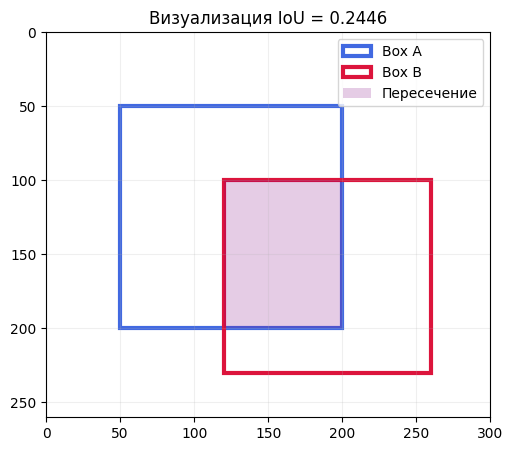

In [ ]:
def intersection_over_union(box_a, box_b):
    # IoU двух рамок формата [x1, y1, x2, y2].
    ax1, ay1, ax2, ay2 = map(float, box_a)
    bx1, by1, bx2, by2 = map(float, box_b)
    inter_x1, inter_y1 = max(ax1, bx1), max(ay1, by1)
    inter_x2, inter_y2 = min(ax2, bx2), min(ay2, by2)
    inter_w = max(0.0, inter_x2 - inter_x1)
    inter_h = max(0.0, inter_y2 - inter_y1)
    intersection = inter_w * inter_h
    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

box_a = [50, 50, 200, 200]
box_b = [120, 100, 260, 230]
example_iou = intersection_over_union(box_a, box_b)
print(f"Численный пример: IoU = {example_iou:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.add_patch(plt.Rectangle(
    (box_a[0], box_a[1]), box_a[2] - box_a[0], box_a[3] - box_a[1],
    fill=False, edgecolor="royalblue", linewidth=3, label="Box A"
))
ax.add_patch(plt.Rectangle(
    (box_b[0], box_b[1]), box_b[2] - box_b[0], box_b[3] - box_b[1],
    fill=False, edgecolor="crimson", linewidth=3, label="Box B"
))
ix1, iy1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
ix2, iy2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
ax.add_patch(plt.Rectangle(
    (ix1, iy1), max(0, ix2 - ix1), max(0, iy2 - iy1),
    facecolor="purple", alpha=0.2, label="Пересечение"
))
ax.set_xlim(0, 300)
ax.set_ylim(260, 0)
ax.set_aspect("equal")
ax.set_title(f"Визуализация IoU = {example_iou:.4f}")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

Фиолетовая область — пересечение рамок. При неизменном пересечении лишняя площадь любой
рамки увеличивает объединение и уменьшает IoU, то есть штрафует неточную локализацию.

### 15. Тестирование на новых изображениях

В качестве новых для модели изображений берутся четыре случайных кадра из отложенного
test split. Они гарантированно не использовались ни для обучения, ни для выбора лучшей
конфигурации. Такой вариант надёжнее случайных картинок из Интернета для узкой микроскопической
области: домен и классы совпадают, а отсутствие утечки проверяется программно.

In [ ]:
# False позволяет выполнить весь ноутбук без интерактивной остановки.
# Можно установить True и загрузить 1-4 внешних изображения крови.
UPLOAD_EXTERNAL_IMAGES = False
PREDICTION_CONFIDENCE = 0.45
NEW_IMAGES_DIR = PROJECT_ROOT / "new_images"
NEW_IMAGES_DIR.mkdir(parents=True, exist_ok=True)

if IN_COLAB and UPLOAD_EXTERNAL_IMAGES:
    from google.colab import files

    uploaded = files.upload()
    for filename, content in uploaded.items():
        (NEW_IMAGES_DIR / filename).write_bytes(content)

    new_image_paths = sorted(
        path for path in NEW_IMAGES_DIR.iterdir()
        if path.suffix.lower() in {".jpg", ".jpeg", ".png"}
    )[:4]
    image_source_title = "пользовательских изображениях"
else:
    new_rng = random.Random(SEED + 100)
    new_image_paths = new_rng.sample(TEST_IMAGE_PATHS, k=min(2, len(TEST_IMAGE_PATHS)))
    train_stems = {p.stem for p in (DATASET_DIR / "images" / "train").glob("*.jpg")}
    assert all(path.stem not in train_stems for path in new_image_paths)
    image_source_title = "невиденных test-изображениях"

if not new_image_paths:
    raise RuntimeError("Не найдено ни одного изображения для inference.")

prediction_results = best_yolo.predict(
    source=[str(path) for path in new_image_paths],
    imgsz=best_record["imgsz"],
    conf=PREDICTION_CONFIDENCE,
    device=DEVICE,
    save=True,
    project=str(RUNS_ROOT / "predict"),
    name="new_unseen_images",
    exist_ok=True,
    verbose=False,
)

prediction_rows = []
n_cols = 2
n_rows = math.ceil(len(new_image_paths) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows), squeeze=False)
for ax, image_path, result in zip(axes.ravel(), new_image_paths, prediction_results):
    rendered = cv2.cvtColor(
        result.plot(line_width=1, font_size=9),
        cv2.COLOR_BGR2RGB,
    )
    ax.imshow(rendered)
    ax.set_title(image_path.name)
    ax.axis("off")
    if result.boxes is not None:
        for xyxy, cls_id, confidence in zip(
            result.boxes.xyxy.cpu().numpy(),
            result.boxes.cls.cpu().numpy().astype(int),
            result.boxes.conf.cpu().numpy(),
        ):
            prediction_rows.append(
                {
                    "image": image_path.name,
                    "class": CLASS_NAMES[cls_id],
                    "confidence": float(confidence),
                    "x1": float(xyxy[0]),
                    "y1": float(xyxy[1]),
                    "x2": float(xyxy[2]),
                    "y2": float(xyxy[3]),
                }
            )
for ax in axes.ravel()[len(new_image_paths):]:
    ax.axis("off")
plt.suptitle(
    f"Предсказания лучшей YOLO на {image_source_title} "
    f"(confidence ≥ {PREDICTION_CONFIDENCE:.2f})",
    y=1.01,
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "best_yolo_predictions.png", dpi=180, bbox_inches="tight")
plt.show()

predictions_df = pd.DataFrame(
    prediction_rows,
    columns=["image", "class", "confidence", "x1", "y1", "x2", "y2"],
)
PREDICTIONS_CSV = PROJECT_ROOT / "new_images_predictions.csv"
predictions_df.to_csv(PREDICTIONS_CSV, index=False)
display(predictions_df.head(20))
print(f"Все предсказания: {PREDICTIONS_CSV}")


На изображениях подписаны класс и confidence каждой рамки. Confidence отражает уверенность
модели, но не гарантирует правильность: проверка локализации требует сравнения с ground truth
по IoU, что выполняется в следующем разделе.

### 16. Анализ ошибок

Для каждого test-изображения предсказания сопоставляются с ground truth внутри класса.
При IoU ≥ 0.50 получается TP; несопоставленное предсказание — FP; несопоставленный истинный
объект — FN. Пара того же класса с 0.10 ≤ IoU < 0.50 отмечается как плохая локализация.

In [ ]:
def load_ground_truth_xyxy(image_path):
    image = Image.open(image_path)
    rows = read_yolo_labels(DATASET_DIR / "labels" / "test" / f"{image_path.stem}.txt")
    boxes, labels = [], []
    for row in rows:
        class_id, x1, y1, x2, y2 = yolo_box_to_xyxy(row, *image.size)
        boxes.append([x1, y1, x2, y2])
        labels.append(class_id)
    return np.asarray(boxes, dtype=float).reshape(-1, 4), np.asarray(labels, dtype=int)

ERROR_CONFIDENCE = 0.25

def analyze_one_image(
    image_path,
    result,
    conf_threshold=ERROR_CONFIDENCE,
    match_threshold=0.50,
):
    gt_boxes, gt_labels = load_ground_truth_xyxy(image_path)
    if result.boxes is None:
        pred_boxes = np.empty((0, 4), dtype=float)
        pred_labels = np.empty(0, dtype=int)
        pred_scores = np.empty(0, dtype=float)
    else:
        scores = result.boxes.conf.cpu().numpy()
        keep = scores >= conf_threshold
        pred_boxes = result.boxes.xyxy.cpu().numpy()[keep]
        pred_labels = result.boxes.cls.cpu().numpy().astype(int)[keep]
        pred_scores = scores[keep]

    candidates = []
    for pred_idx in range(len(pred_boxes)):
        for gt_idx in range(len(gt_boxes)):
            if pred_labels[pred_idx] == gt_labels[gt_idx]:
                iou = intersection_over_union(pred_boxes[pred_idx], gt_boxes[gt_idx])
                candidates.append((iou, pred_idx, gt_idx))
    matched_pred, matched_gt, matches = set(), set(), []
    for iou, pred_idx, gt_idx in sorted(candidates, reverse=True):
        if iou < match_threshold:
            continue
        if pred_idx not in matched_pred and gt_idx not in matched_gt:
            matched_pred.add(pred_idx)
            matched_gt.add(gt_idx)
            matches.append((pred_idx, gt_idx, iou))

    fp_indices = [idx for idx in range(len(pred_boxes)) if idx not in matched_pred]
    fn_indices = [idx for idx in range(len(gt_boxes)) if idx not in matched_gt]
    bad_localizations = []
    for pred_idx in fp_indices:
        for gt_idx in fn_indices:
            if pred_labels[pred_idx] == gt_labels[gt_idx]:
                iou = intersection_over_union(pred_boxes[pred_idx], gt_boxes[gt_idx])
                if 0.10 <= iou < match_threshold:
                    bad_localizations.append((pred_idx, gt_idx, iou))

    return {
        "image_path": image_path,
        "gt_boxes": gt_boxes,
        "gt_labels": gt_labels,
        "pred_boxes": pred_boxes,
        "pred_labels": pred_labels,
        "pred_scores": pred_scores,
        "matches": matches,
        "fp_indices": fp_indices,
        "fn_indices": fn_indices,
        "bad_localizations": bad_localizations,
    }

all_test_results = best_yolo.predict(
    source=[str(path) for path in TEST_IMAGE_PATHS],
    imgsz=best_record["imgsz"], conf=0.001, device=DEVICE, verbose=False
)
analyses = [
    analyze_one_image(path, result)
    for path, result in zip(TEST_IMAGE_PATHS, all_test_results)
]
error_summary_df = pd.DataFrame(
    [
        {
            "image": item["image_path"].name,
            "TP": len(item["matches"]),
            "FP": len(item["fp_indices"]),
            "FN": len(item["fn_indices"]),
            "bad_localization_pairs": len(item["bad_localizations"]),
        }
        for item in analyses
    ]
)
display(error_summary_df.describe().round(2))
print(
    f"Итог по test при confidence >= {ERROR_CONFIDENCE:.2f}:",
    error_summary_df[["TP", "FP", "FN"]].sum().to_dict(),
)

In [ ]:
def pure_fp_indices(item):
    localization_predictions = {
        pred_idx for pred_idx, _, _ in item["bad_localizations"]
    }
    return [
        idx for idx in item["fp_indices"]
        if idx not in localization_predictions
    ]

def pure_fn_indices(item):
    localization_targets = {
        gt_idx for _, gt_idx, _ in item["bad_localizations"]
    }
    return [
        idx for idx in item["fn_indices"]
        if idx not in localization_targets
    ]

def has_example(item, kind):
    if kind == "True Positive":
        return bool(item["matches"])
    if kind == "False Positive":
        return bool(pure_fp_indices(item))
    if kind == "False Negative":
        return bool(pure_fn_indices(item))
    return bool(item["bad_localizations"])

def candidate_score(item, kind):
    if kind == "True Positive":
        return max(
            float(item["pred_scores"][pred_idx])
            for pred_idx, _, _ in item["matches"]
        )
    if kind == "False Positive":
        return max(float(item["pred_scores"][idx]) for idx in pure_fp_indices(item))
    if kind == "False Negative":
        return -len(pure_fp_indices(item)) - len(pure_fn_indices(item))
    return max(iou for _, _, iou in item["bad_localizations"])

def select_example(kind, excluded_paths=None):
    excluded_paths = excluded_paths or set()
    candidates = [
        item for item in analyses
        if has_example(item, kind) and item["image_path"] not in excluded_paths
    ]
    return max(candidates, key=lambda item: candidate_score(item, kind)) if candidates else None

def draw_labeled_box(image, box, color, label, text_above=True):
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(image, (x1, y1), (x2, y2), color, 3)
    text_y = max(16, y1 - 6) if text_above else min(image.shape[0] - 6, y2 + 16)
    cv2.putText(
        image,
        label,
        (x1, text_y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.48,
        color,
        2,
        cv2.LINE_AA,
    )

def render_analysis(ax, item, kind):
    if item is None:
        ax.text(0.5, 0.5, "Реальный пример\nне найден", ha="center", va="center", fontsize=13)
        ax.set_title(kind)
        ax.axis("off")
        return

    image = np.asarray(Image.open(item["image_path"]).convert("RGB")).copy()
    details = ""

    if kind == "True Positive":
        pred_idx, gt_idx, iou = max(
            item["matches"],
            key=lambda match: float(item["pred_scores"][match[0]]),
        )
        class_id = int(item["pred_labels"][pred_idx])
        score = float(item["pred_scores"][pred_idx])
        draw_labeled_box(
            image,
            item["gt_boxes"][gt_idx],
            (30, 200, 30),
            f"GT {CLASS_NAMES[class_id]}",
        )
        draw_labeled_box(
            image,
            item["pred_boxes"][pred_idx],
            (30, 130, 255),
            f"TP {CLASS_NAMES[class_id]} {score:.2f}",
            text_above=False,
        )
        details = f"IoU={iou:.2f}, confidence={score:.2f}"

    elif kind == "False Positive":
        pred_idx = max(
            pure_fp_indices(item),
            key=lambda idx: float(item["pred_scores"][idx]),
        )
        class_id = int(item["pred_labels"][pred_idx])
        score = float(item["pred_scores"][pred_idx])
        draw_labeled_box(
            image,
            item["pred_boxes"][pred_idx],
            (220, 30, 180),
            f"FP {CLASS_NAMES[class_id]} {score:.2f}",
        )
        details = f"Ложное обнаружение, confidence={score:.2f}"

    elif kind == "False Negative":
        gt_idx = pure_fn_indices(item)[0]
        class_id = int(item["gt_labels"][gt_idx])
        draw_labeled_box(
            image,
            item["gt_boxes"][gt_idx],
            (255, 40, 40),
            f"FN {CLASS_NAMES[class_id]}",
        )
        details = "Истинный объект не обнаружен"

    else:
        pred_idx, gt_idx, iou = max(item["bad_localizations"], key=lambda match: match[2])
        class_id = int(item["pred_labels"][pred_idx])
        score = float(item["pred_scores"][pred_idx])
        draw_labeled_box(
            image,
            item["gt_boxes"][gt_idx],
            (255, 170, 0),
            f"GT {CLASS_NAMES[class_id]}",
        )
        draw_labeled_box(
            image,
            item["pred_boxes"][pred_idx],
            (255, 210, 0),
            f"Prediction {score:.2f}",
            text_above=False,
        )
        details = f"Недостаточный IoU={iou:.2f}"

    ax.imshow(image)
    ax.set_title(f"{kind}: {item['image_path'].name}\n{details}")
    ax.axis("off")

categories = ["True Positive", "False Positive", "False Negative", "Плохая локализация"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
selected_examples = {}
used_paths = set()
for ax, category in zip(axes.ravel(), categories):
    selected = select_example(category, used_paths)
    selected_examples[category] = selected
    if selected is not None:
        used_paths.add(selected["image_path"])
    render_analysis(ax, selected, category)

plt.suptitle(
    f"Примеры результатов лучшей YOLO на test (confidence ≥ {ERROR_CONFIDENCE:.2f})\n"
    "В каждом окне выделен только один анализируемый объект",
    y=1.01,
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "best_yolo_error_examples.png", dpi=180, bbox_inches="tight")
plt.show()


### 17. Вывод

Следующая ячейка автоматически формирует итог по фактическим результатам текущего запуска.

In [ ]:
best_experiment_row = experiment_table.iloc[0]
best_architecture_row = comparison_df.loc[comparison_df["mAP50-95"].idxmax()]
fastest_architecture_row = comparison_df.loc[comparison_df["inference_ms"].idxmin()]
speed_ratio = comparison_df["inference_ms"].max() / max(comparison_df["inference_ms"].min(), 1e-9)
class_totals = object_stats["total"]
imbalance_ratio = class_totals.max() / max(class_totals.min(), 1)

print("ИТОГОВЫЙ ВЫВОД")
print("-" * 70)
print(
    f"Обучены три YOLO-конфигурации и Faster R-CNN. Лучший YOLO-эксперимент по "
    f"validation mAP50-95 — {best_experiment_row['experiment']} "
    f"({best_experiment_row['model']}): {best_experiment_row['mAP50-95']:.4f}."
)
print(
    f"На test среди сравниваемых архитектур лучший mAP50-95 получила "
    f"{best_architecture_row['Model']}: {best_architecture_row['mAP50-95']:.4f}."
)
print(
    f"Самая быстрая модель — {fastest_architecture_row['Model']} "
    f"({fastest_architecture_row['inference_ms']:.2f} мс/изображение); "
    f"отношение времени самой медленной к самой быстрой составило {speed_ratio:.2f}×."
)
print(
    f"Соотношение самого частого и самого редкого классов равно {imbalance_ratio:.2f}×, "
    "поэтому поклассовые метрики и примеры ошибок важны наряду со средним mAP."
)
if "YOLO" in fastest_architecture_row["Model"]:
    print("Для real-time сценария предпочтительнее YOLO: она оказалась быстрее и имеет более простой единый pipeline.")
else:
    print("В этом запуске Faster R-CNN измерена быстрее; вывод следует перепроверить повторным benchmark из-за малого test набора.")
if best_architecture_row["Model"].startswith("YOLO"):
    print("Для BCCD по критерию качества и удобства выбран лучший вариант YOLO.")
else:
    print("Если приоритет — максимальная точность на BCCD, выбран Faster R-CNN; для real-time всё равно следует учитывать скорость YOLO.")
print(
    "Работа продемонстрировала воспроизводимый pipeline: загрузку и проверку данных, "
    "transfer learning, validation-based выбор гиперпараметров, test-оценку, IoU, inference "
    "на невиденных изображениях и анализ TP/FP/FN/ошибок локализации."
)

ИТОГОВЫЙ ВЫВОД
----------------------------------------------------------------------
Обучены три YOLO-конфигурации и Faster R-CNN. Лучший YOLO-эксперимент по validation mAP50-95 — n_tuned_aug (yolo26n.pt): 0.6073.
На test среди сравниваемых архитектур лучший mAP50-95 получила YOLO26 (n_tuned_aug): 0.6015.
Самая быстрая модель — YOLO26 (n_tuned_aug) (1.72 мс/изображение); отношение времени самой медленной к самой быстрой составило 8.41×.
Соотношение самого частого и самого редкого классов равно 11.50×, поэтому поклассовые метрики и примеры ошибок важны наряду со средним mAP.
Для real-time сценария предпочтительнее YOLO: она оказалась быстрее и имеет более простой единый pipeline.
Для BCCD по критерию качества и удобства выбран лучший вариант YOLO.
Работа продемонстрировала воспроизводимый pipeline: загрузку и проверку данных, transfer learning, validation-based выбор гиперпараметров, test-оценку, IoU, inference на невиденных изображениях и анализ TP/FP/FN/ошибок локализации.


### 18. Сохранение артефактов

In [ ]:
EXPORT_DIR = PROJECT_ROOT / "submission_artifacts"
if EXPORT_DIR.exists():
    shutil.rmtree(EXPORT_DIR)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

experiment_table.to_csv(EXPORT_DIR / "yolo_experiments.csv", index=False)
comparison_df.to_csv(EXPORT_DIR / "architecture_comparison.csv", index=False)
fr_history_df.to_csv(EXPORT_DIR / "faster_rcnn_history.csv", index=False)

files_to_copy = [
    ENVIRONMENT_JSON,
    DATASET_PROVENANCE_JSON,
    PREDICTIONS_CSV,
    FR_CHECKPOINT,
]
for path in files_to_copy:
    if Path(path).exists():
        shutil.copy2(path, EXPORT_DIR / Path(path).name)

if RUNS_ROOT.exists():
    shutil.copytree(RUNS_ROOT, EXPORT_DIR / "runs", dirs_exist_ok=True)

archive_base = (
    Path("/content/lab_02_yolo_artifacts")
    if IN_COLAB
    else PROJECT_ROOT / "lab_02_yolo_artifacts"
)
archive_path = shutil.make_archive(
    str(archive_base),
    "zip",
    root_dir=EXPORT_DIR,
)
archive_size_mb = Path(archive_path).stat().st_size / 1024**2
print(f"Архив подготовлен: {archive_path}")
print(f"Размер архива: {archive_size_mb:.2f} MB")

if IN_COLAB:
    from google.colab import files
    files.download(archive_path)
else:
    print("Локальный запуск: архив сохранён по указанному пути.")


Архив подготовлен: /content/lab_02_yolo_artifacts.zip
Размер архива: 153.65 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>